In [1]:
import pandas as pd

url="https://raw.githubusercontent.com/IBM/telco-customer-churn-on-icp4d/master/data/Telco-Customer-Churn.csv"

df=pd.read_csv(url)

df.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,...,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,...,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,...,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,...,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,...,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [2]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   object 
 1   gender            7043 non-null   object 
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   object 
 4   Dependents        7043 non-null   object 
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   object 
 7   MultipleLines     7043 non-null   object 
 8   InternetService   7043 non-null   object 
 9   OnlineSecurity    7043 non-null   object 
 10  OnlineBackup      7043 non-null   object 
 11  DeviceProtection  7043 non-null   object 
 12  TechSupport       7043 non-null   object 
 13  StreamingTV       7043 non-null   object 
 14  StreamingMovies   7043 non-null   object 
 15  Contract          7043 non-null   object 
 16  PaperlessBilling  7043 non-null   object 


In [3]:
print(df['Churn'].value_counts())

Churn
No     5174
Yes    1869
Name: count, dtype: int64


In [4]:
df.columns

Index(['customerID', 'gender', 'SeniorCitizen', 'Partner', 'Dependents',
       'tenure', 'PhoneService', 'MultipleLines', 'InternetService',
       'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport',
       'StreamingTV', 'StreamingMovies', 'Contract', 'PaperlessBilling',
       'PaymentMethod', 'MonthlyCharges', 'TotalCharges', 'Churn'],
      dtype='object')

In [5]:
df.shape

(7043, 21)

In [6]:
df.describe()

,SeniorCitizen,tenure,MonthlyCharges
count,7043.000000,7043.000000,7043.000000
mean,0.162147,32.371149,64.761692
std,0.368612,24.559481,30.090047
min,0.000000,0.000000,18.250000
25%,0.000000,9.000000,35.500000
50%,0.000000,29.000000,70.350000
75%,0.000000,55.000000,89.850000
max,1.000000,72.000000,118.750000


In [7]:
df.isnull().sum()

,0
customerID,0
gender,0
SeniorCitizen,0
Partner,0
Dependents,0
tenure,0
PhoneService,0
MultipleLines,0
InternetService,0
OnlineSecurity,0


In [8]:
df['TotalCharges'] = pd.to_numeric(df['TotalCharges'], errors='coerce').fillna(0)

df = df.drop('customerID', axis=1)

print("Shape:", df.shape)
print("Nulls:", df.isnull().sum().sum())

Shape: (7043, 20)
Nulls: 0


In [9]:
print(df['Churn'].value_counts(dropna=False))
print("Missing values:", df['Churn'].isnull().sum())

Churn
No     5174
Yes    1869
Name: count, dtype: int64
Missing values: 0


In [10]:
df_encoded = pd.get_dummies(df.drop('Churn', axis=1), drop_first=True)

In [11]:
df = df.dropna(subset=['Churn']).copy()

X = df_encoded
y = df['Churn'].map({'No': 0, 'Yes': 1})

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print("Train:", X_train.shape)
print("Test:", X_test.shape)

Train: (5634, 30)
Test: (1409, 30)


In [13]:
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, precision_score, recall_score, roc_auc_score, average_precision_score

model = LogisticRegression(max_iter=10000)
model.fit(X_train, y_train)

pred_lr = model.predict(X_test)
proba_lr = model.predict_proba(X_test)[:, 1]

print("LogReg Accuracy:", round(accuracy_score(y_test, pred_lr), 4))
print("LogReg F1:", round(f1_score(y_test, pred_lr), 4))
print("LogReg Precision:", round(precision_score(y_test, pred_lr), 4))
print("LogReg Recall:", round(recall_score(y_test, pred_lr), 4))
print("LogReg ROC-AUC:", round(roc_auc_score(y_test, proba_lr), 4))
print("LogReg PR-AUC:", round(average_precision_score(y_test, proba_lr), 4))

LogReg Accuracy: 0.807
LogReg F1: 0.6058
LogReg Precision: 0.6614
LogReg Recall: 0.5588
LogReg ROC-AUC: 0.8424
LogReg PR-AUC: 0.6342


In [14]:
from xgboost import XGBClassifier

xgb = XGBClassifier(random_state=42, eval_metric='logloss')
xgb.fit(X_train, y_train)

pred_xgb = xgb.predict(X_test)
proba_xgb = xgb.predict_proba(X_test)[:, 1]

print("XGB Accuracy:", round(accuracy_score(y_test, pred_xgb), 4))
print("XGB F1:", round(f1_score(y_test, pred_xgb), 4))
print("XGB Precision:", round(precision_score(y_test, pred_xgb), 4))
print("XGB Recall:", round(recall_score(y_test, pred_xgb), 4))
print("XGB ROC-AUC:", round(roc_auc_score(y_test, proba_xgb), 4))
print("XGB PR-AUC:", round(average_precision_score(y_test, proba_xgb), 4))

XGB Accuracy: 0.7764
XGB F1: 0.5532
XGB Precision: 0.5891
XGB Recall: 0.5214
XGB ROC-AUC: 0.8183
XGB PR-AUC: 0.6141


In [15]:
scale = (y_train == 0).sum() / (y_train == 1).sum()

xgb2 = XGBClassifier(random_state=42, eval_metric='logloss', scale_pos_weight=scale)
xgb2.fit(X_train, y_train)

pred_xgb2 = xgb2.predict(X_test)
proba_xgb2 = xgb2.predict_proba(X_test)[:, 1]

print("XGB balanced Accuracy:", round(accuracy_score(y_test, pred_xgb2), 4))
print("XGB balanced F1:", round(f1_score(y_test, pred_xgb2), 4))
print("XGB balanced Precision:", round(precision_score(y_test, pred_xgb2), 4))
print("XGB balanced Recall:", round(recall_score(y_test, pred_xgb2), 4))
print("XGB balanced ROC-AUC:", round(roc_auc_score(y_test, proba_xgb2), 4))
print("XGB balanced PR-AUC:", round(average_precision_score(y_test, proba_xgb2), 4))

XGB balanced Accuracy: 0.7573
XGB balanced F1: 0.5948
XGB balanced Precision: 0.534
XGB balanced Recall: 0.6711
XGB balanced ROC-AUC: 0.8185
XGB balanced PR-AUC: 0.621


In [16]:
results = []

for name, pred, proba in [
    ('Logistic Regression', pred_lr, proba_lr),
    ('XGBoost', pred_xgb, proba_xgb),
    ('XGBoost (balanced)', pred_xgb2, proba_xgb2),
]:
    results.append({
        'Model': name,
        'Accuracy': round(accuracy_score(y_test, pred), 4),
        'F1': round(f1_score(y_test, pred), 4),
        'Precision': round(precision_score(y_test, pred), 4),
        'Recall': round(recall_score(y_test, pred), 4),
        'ROC-AUC': round(roc_auc_score(y_test, proba), 4),
        'PR-AUC': round(average_precision_score(y_test, proba), 4),
    })

results_df = pd.DataFrame(results)
results_df

,Model,Accuracy,F1,Precision,Recall,ROC-AUC,PR-AUC
0,Logistic Regression,0.8070,0.6058,0.6614,0.5588,0.8424,0.6342
1,XGBoost,0.7764,0.5532,0.5891,0.5214,0.8183,0.6141
2,XGBoost (balanced),0.7573,0.5948,0.5340,0.6711,0.8185,0.6210


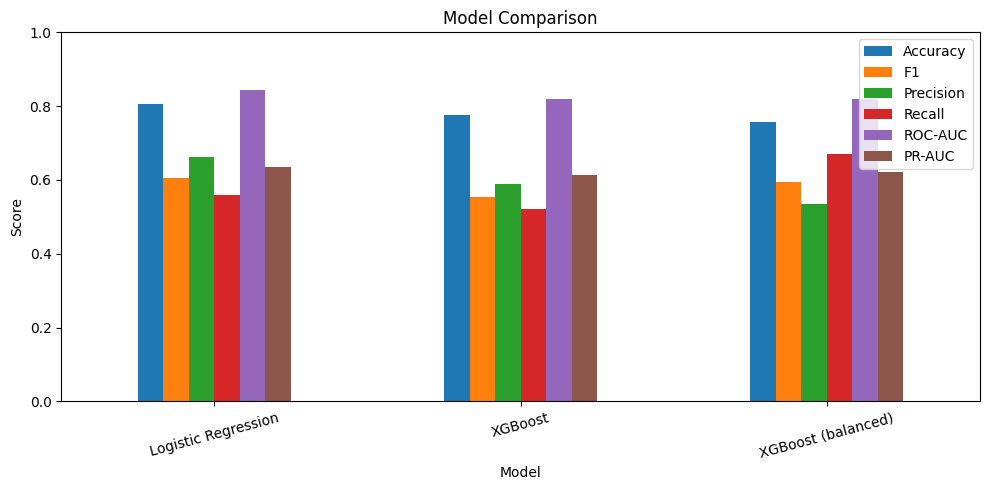

In [17]:
import matplotlib.pyplot as plt

results_df.set_index('Model')[['Accuracy', 'F1', 'Precision', 'Recall', 'ROC-AUC', 'PR-AUC']].plot(
    kind='bar', figsize=(10, 5)
)
plt.title('Model Comparison')
plt.ylabel('Score')
plt.ylim(0, 1)
plt.xticks(rotation=15)
plt.tight_layout()
plt.savefig('model_comparison.png', dpi=150)
plt.show()

In [18]:
importance = pd.DataFrame({
    'feature': X_train.columns,
    'importance': xgb.feature_importances_
}).sort_values('importance', ascending=False)

print(importance.head(10))

                           feature  importance
10     InternetService_Fiber optic    0.426852
25               Contract_Two year    0.172697
24               Contract_One year    0.088898
11              InternetService_No    0.081581
23             StreamingMovies_Yes    0.024916
1                           tenure    0.021486
9                MultipleLines_Yes    0.014222
28  PaymentMethod_Electronic check    0.014131
19                 TechSupport_Yes    0.012963
7                 PhoneService_Yes    0.012768


In [19]:
import numpy as np

probs = proba_lr

offer_cost = 500
customer_value = 2000
top_10_pct = int(len(probs) * 0.10)

expected_value = probs * customer_value - offer_cost
sorted_idx = np.argsort(-expected_value)
top_model = sorted_idx[:top_10_pct]

def net_value(indices):
    return (probs[indices] * customer_value).sum() - len(indices) * offer_cost

model_net = net_value(top_model)

np.random.seed(42)
random_nets = []
for _ in range(100):
    idx = np.random.choice(len(probs), top_10_pct, replace=False)
    random_nets.append(net_value(idx))

random_avg = np.mean(random_nets)

print("Top 10% by model — estimated net value:", round(model_net, 0))
print("Top 10% random (avg of 100) — estimated net value:", round(random_avg, 0))
print("Difference:", round(model_net - random_avg, 0))

Top 10% by model — estimated net value: 133411.0
Top 10% random (avg of 100) — estimated net value: 4912.0
Difference: 128500.0


In [20]:
top_10_churn_rate = y_test.iloc[top_model].mean()
overall_churn_rate = y_test.mean()

print("Churn rate in top 10%:", round(top_10_churn_rate, 3))
print("Overall churn rate:", round(overall_churn_rate, 3))
print("Lift@10%:", round(top_10_churn_rate / overall_churn_rate, 2), "x")

Churn rate in top 10%: 0.75
Overall churn rate: 0.265
Lift@10%: 2.83 x


In [21]:
new_mask = X_test['tenure'] < 3
old_mask = ~new_mask

print("New customers (tenure < 3):", new_mask.sum())
print("Recall on new:", round(recall_score(y_test[new_mask], model.predict(X_test[new_mask])), 3) if new_mask.sum() > 0 else "N/A")
print("Recall on old:", round(recall_score(y_test[old_mask], model.predict(X_test[old_mask])), 3))

New customers (tenure < 3): 180
Recall on new: 0.658
Recall on old: 0.517
